# Lab Assignment: Skin Lesion Boundary Detection Using Canny Edge Detection

**Dataset:** HAM10000 (Skin Cancer MNIST) – downloaded with `kagglehub`
**Tools:** Python, OpenCV, NumPy, Pandas, Matplotlib

**Pipeline:** Original → Grayscale → Gaussian Filter → Canny → Lesion Boundary → Area & Perimeter

> Run all cells from top to bottom (`Runtime → Run all`). Everything (images, tables, answers) is generated automatically.

## Task 1 — Load the Image

In [1]:
!pip -q install kagglehub

In [2]:
import os, glob, math, warnings
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import kagglehub
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110
SEED = 42

# ---- Download HAM10000 (your code) ----
path = kagglehub.dataset_download("kmader/skin-cancer-mnist-ham10000")
print("Path to dataset files:", path)

# ---- Index all images + metadata ----
img_paths = {os.path.splitext(os.path.basename(p))[0]: p
             for p in glob.glob(os.path.join(path, "**", "*.jpg"), recursive=True)}
meta_file = glob.glob(os.path.join(path, "**", "HAM10000_metadata.csv"), recursive=True)[0]
meta = pd.read_csv(meta_file)
print(f"Total images found: {len(img_paths)}")
meta.head()

Using Colab cache for faster access to the 'skin-cancer-mnist-ham10000' dataset.
Path to dataset files: /kaggle/input/skin-cancer-mnist-ham10000
Total images found: 10015


,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear


We pick **5 images**, one from each of five different lesion classes, so the method is tested on different appearances:
`mel` (melanoma), `nv` (melanocytic nevus), `bkl` (benign keratosis), `bcc` (basal cell carcinoma), `akiec` (actinic keratosis).

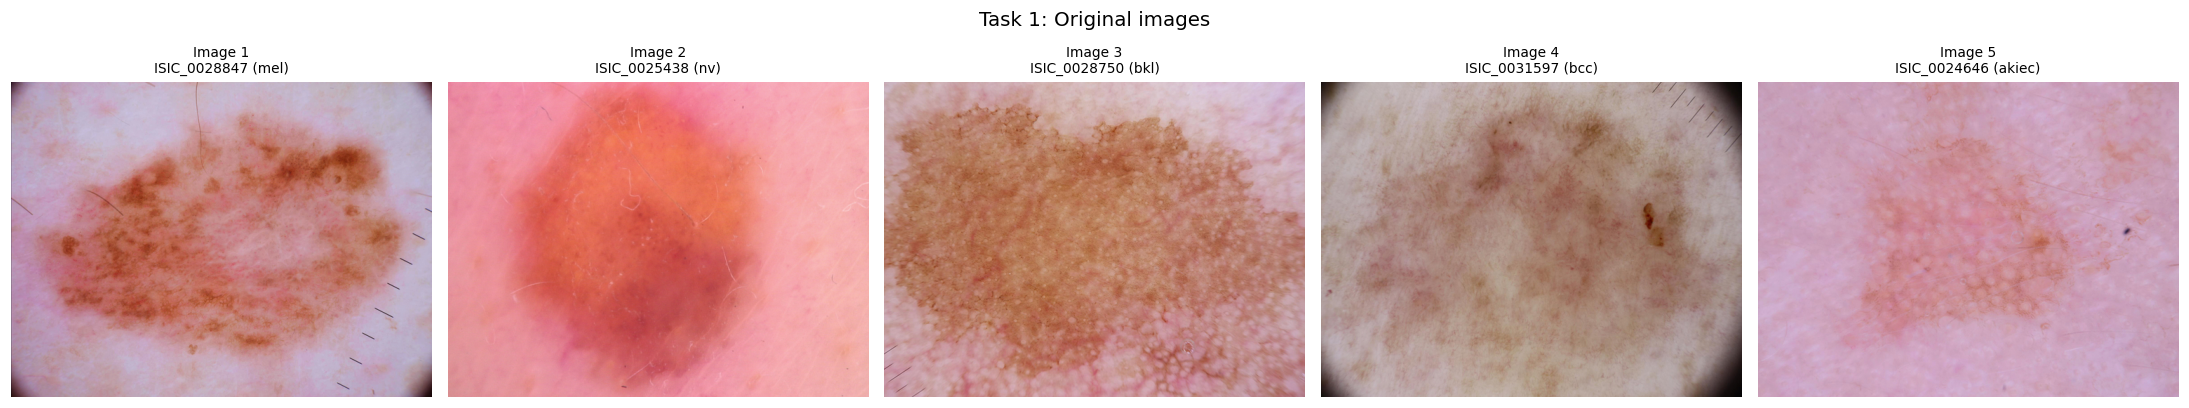

Image size (H, W, C): (450, 600, 3)


In [3]:
classes = ["mel", "nv", "bkl", "bcc", "akiec"]
images, names, labels = [], [], []
for i, dx in enumerate(classes, 1):
    row = meta[(meta.dx == dx) & (meta.image_id.isin(img_paths))].sample(1, random_state=SEED).iloc[0]
    bgr = cv2.imread(img_paths[row.image_id])
    images.append(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
    names.append(f"Image {i}")
    labels.append(f"{row.image_id} ({dx})")

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, im, n, l in zip(axes, images, names, labels):
    ax.imshow(im); ax.set_title(f"{n}\n{l}", fontsize=9); ax.axis("off")
plt.suptitle("Task 1: Original images", fontsize=13)
plt.tight_layout(); plt.show()
print("Image size (H, W, C):", images[0].shape)

## Helper functions

* `analyze()` runs the whole pipeline (grayscale → Gaussian → Canny with 3 thresholds → boundary).
* **Boundary extraction** (Task 5): Canny edges → *morphological closing* (to close small gaps in the edge ring) → *contour detection* → pick the largest contour that does not touch the image border (this ignores the dark vignette/corners of dermoscopy images).
* **Reference mask:** because HAM10000 has no lesion masks in this download, an *Otsu-threshold* segmentation is used as an approximate reference. It lets us choose the best threshold **objectively** (highest IoU with the reference) instead of just by eye.

In [4]:
THRESHOLDS = [(50, 100), (100, 200), (150, 250)]
KERNEL = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))


def select_contour(contours, shape):
    """Largest contour (>1% of image) that does not touch the image border."""
    H, W = shape[:2]
    cands = []
    for c in contours:
        a = cv2.contourArea(c)
        if a < 0.01 * H * W:
            continue
        x, y, w, h = cv2.boundingRect(c)
        touches = x <= 1 or y <= 1 or x + w >= W - 1 or y + h >= H - 1
        cands.append((touches, -a, c))
    if not cands:
        return None
    cands.sort(key=lambda t: (t[0], t[1]))
    return cands[0][2]


def boundary_from_edges(edges):
    """Edges -> closing -> external contours -> lesion contour + filled mask."""
    closed = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, KERNEL, iterations=2)
    contours, _ = cv2.findContours(closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    c = select_contour(contours, edges.shape)
    mask = np.zeros_like(edges)
    if c is not None:
        cv2.drawContours(mask, [c], -1, 255, thickness=cv2.FILLED)
    return mask, c


def reference_mask(gray):
    """Approximate lesion mask using Otsu thresholding (lesion = darker than skin)."""
    b = cv2.GaussianBlur(gray, (7, 7), 0)
    _, m = cv2.threshold(b, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9))
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, k)
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, k, iterations=2)
    contours, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    c = select_contour(contours, m.shape)
    ref = np.zeros_like(m)
    if c is not None:
        cv2.drawContours(ref, [c], -1, 255, thickness=cv2.FILLED)
    return ref, c


def iou(a, b):
    a, b = a > 0, b > 0
    union = np.logical_or(a, b).sum()
    return np.logical_and(a, b).sum() / union if union else 0.0


def edge_metrics(edges, ref_contour, shape, tol=5, far=20):
    """noise  = share of edge pixels farther than `far` px from the reference boundary
       f1     = edge F-score against the reference boundary with `tol` px tolerance"""
    if ref_contour is None or edges.sum() == 0:
        return dict(noise=1.0, precision=0.0, recall=0.0, f1=0.0)
    refb = np.zeros(shape[:2], np.uint8)
    cv2.drawContours(refb, [ref_contour], -1, 255, 1)
    d_ref = cv2.distanceTransform(np.where(refb > 0, 0, 255).astype(np.uint8), cv2.DIST_L2, 3)
    d_edge = cv2.distanceTransform(np.where(edges > 0, 0, 255).astype(np.uint8), cv2.DIST_L2, 3)
    noise = float((d_ref[edges > 0] > far).mean())
    precision = float((d_ref[edges > 0] <= tol).mean())
    recall = float((d_edge[refb > 0] <= tol).mean())
    f1 = 0.0 if precision + recall == 0 else 2 * precision * recall / (precision + recall)
    return dict(noise=noise, precision=precision, recall=recall, f1=f1)


def analyze(rgb):
    """Full pipeline for one image."""
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)                 # Task 2
    blur = cv2.GaussianBlur(gray, (5, 5), 1.5)                   # Task 2
    ref_mask, ref_c = reference_mask(gray)
    res = {}
    for lo, hi in THRESHOLDS:                                    # Task 3
        e = cv2.Canny(blur, lo, hi)
        m, c = boundary_from_edges(e)
        met = edge_metrics(e, ref_c, e.shape)
        res[(lo, hi)] = dict(edges=e, mask=m, contour=c, iou=iou(m, ref_mask),
                             density=float((e > 0).mean()), **met)
    best = max(res, key=lambda k: (round(res[k]["iou"], 2), -round(res[k]["noise"], 2), k[0]))   # Task 4 (ties -> cleaner/higher threshold)
    return dict(gray=gray, blur=blur, ref_mask=ref_mask, results=res, best=best)


def measure(contour, mask):
    """Area (filled pixels) and perimeter (contour length in pixels)."""
    if contour is None:
        return 0, 0.0
    return int(cv2.countNonZero(mask)), float(cv2.arcLength(contour, True))


def overlay(rgb, contour, color=(0, 255, 0), th=3):
    out = rgb.copy()
    if contour is not None:
        cv2.drawContours(out, [contour], -1, color, th)
    return out

## Task 2 — Preprocessing (Grayscale + Gaussian filter)

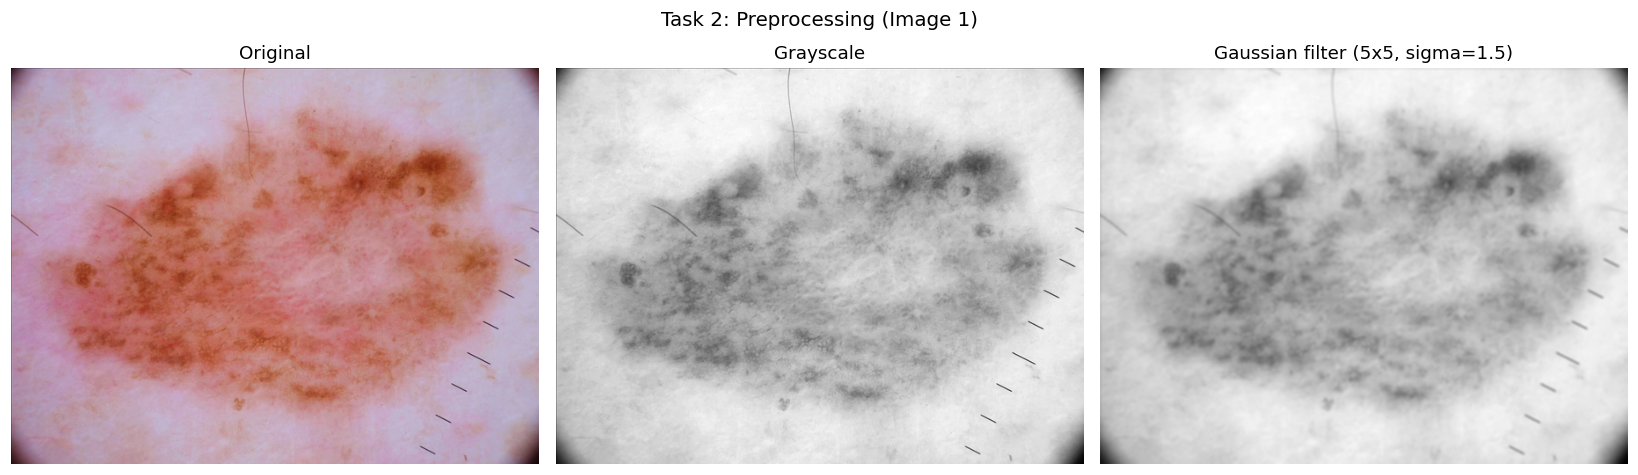

In [5]:
analyses = [analyze(im) for im in images]       # run the pipeline on all 5 images
A = analyses[0]                                  # detailed walk-through uses Image 1

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].imshow(images[0]);                axes[0].set_title("Original")
axes[1].imshow(A["gray"], cmap="gray");   axes[1].set_title("Grayscale")
axes[2].imshow(A["blur"], cmap="gray");   axes[2].set_title("Gaussian filter (5x5, sigma=1.5)")
for ax in axes: ax.axis("off")
plt.suptitle("Task 2: Preprocessing (Image 1)", fontsize=13)
plt.tight_layout(); plt.show()

## Task 3 — Canny Edge Detection with three threshold settings

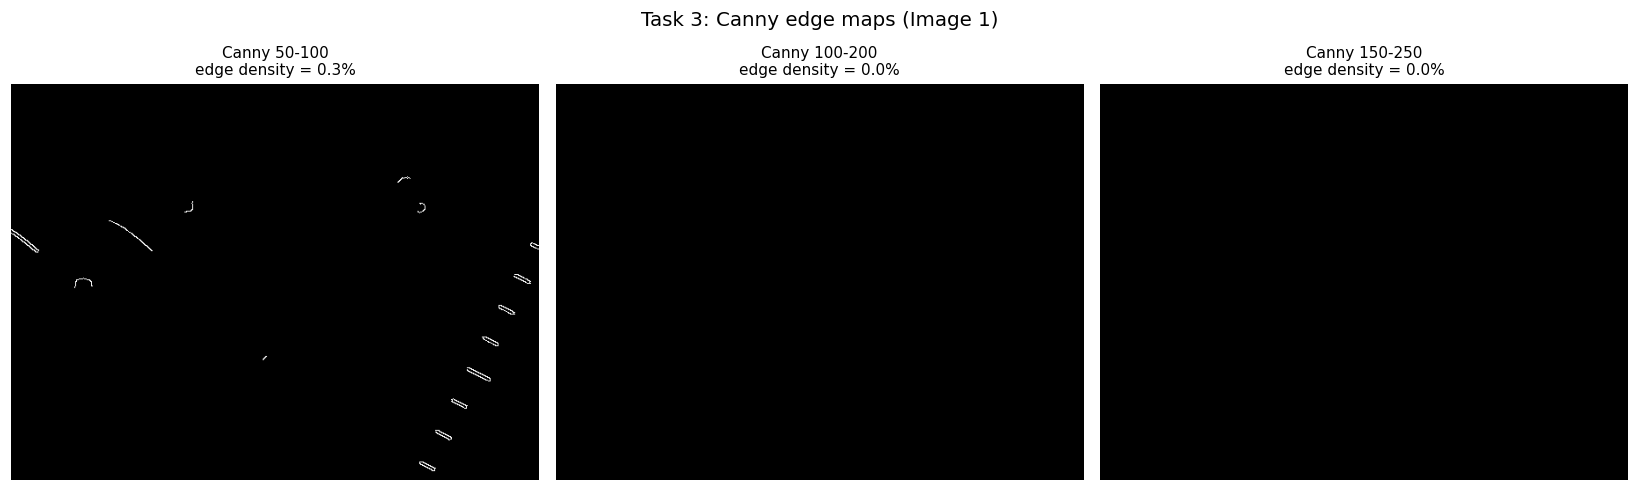

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, (k, r) in zip(axes, A["results"].items()):
    ax.imshow(r["edges"], cmap="gray")
    ax.set_title(f"Canny {k[0]}-{k[1]}\nedge density = {r['density']*100:.1f}%", fontsize=10)
    ax.axis("off")
plt.suptitle("Task 3: Canny edge maps (Image 1)", fontsize=13)
plt.tight_layout(); plt.show()

## Task 4 — Select the best threshold

Each edge map is turned into a lesion contour (see helper functions) and compared with the reference lesion mask.
* **IoU** (higher = better overlap with the lesion)
* **Noise** (lower = fewer spurious edges, e.g. hair, texture, far from the lesion border)

The threshold with the highest IoU (ties broken by lower noise) is selected.

,Threshold,Edge density %,Noise ratio,Edge F1,IoU with reference
0,50-100,0.27,0.768,0.004,0.0
1,100-200,0.00,1.000,0.000,0.0
2,150-250,0.00,1.000,0.000,0.0



>>> Best threshold for Image 1: Canny 50-100


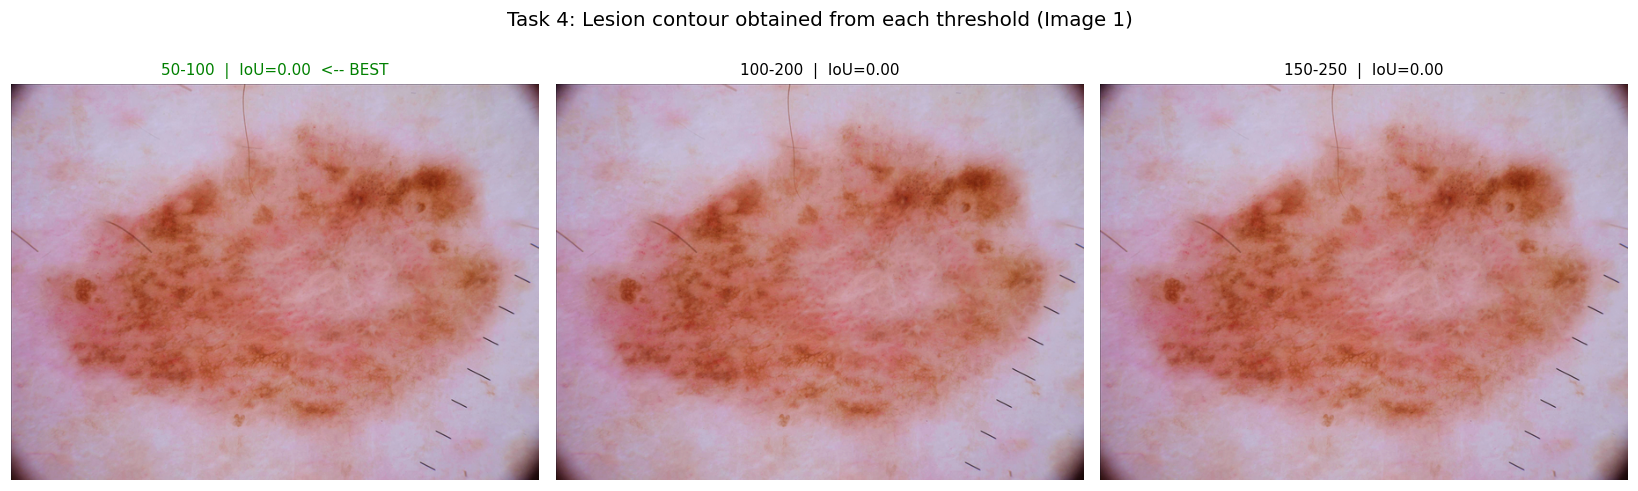

In [7]:
rows = []
for k, r in A["results"].items():
    rows.append({"Threshold": f"{k[0]}-{k[1]}", "Edge density %": round(r["density"]*100, 2),
                 "Noise ratio": round(r["noise"], 3), "Edge F1": round(r["f1"], 3),
                 "IoU with reference": round(r["iou"], 3)})
t4 = pd.DataFrame(rows)
display(t4)
print(f"\n>>> Best threshold for Image 1: Canny {A['best'][0]}-{A['best'][1]}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, (k, r) in zip(axes, A["results"].items()):
    ax.imshow(overlay(images[0], r["contour"]))
    star = "  <-- BEST" if k == A["best"] else ""
    ax.set_title(f"{k[0]}-{k[1]}  |  IoU={r['iou']:.2f}{star}", fontsize=10,
                 color="green" if k == A["best"] else "black")
    ax.axis("off")
plt.suptitle("Task 4: Lesion contour obtained from each threshold (Image 1)", fontsize=13)
plt.tight_layout(); plt.show()

## Task 5 & 6 — Lesion boundary, area and perimeter

* Boundary: Canny edges → morphological closing → contour detection → largest non-border contour.
* **Area** = number of pixels inside the contour. **Perimeter** = length of the contour in pixels (`cv2.arcLength`).

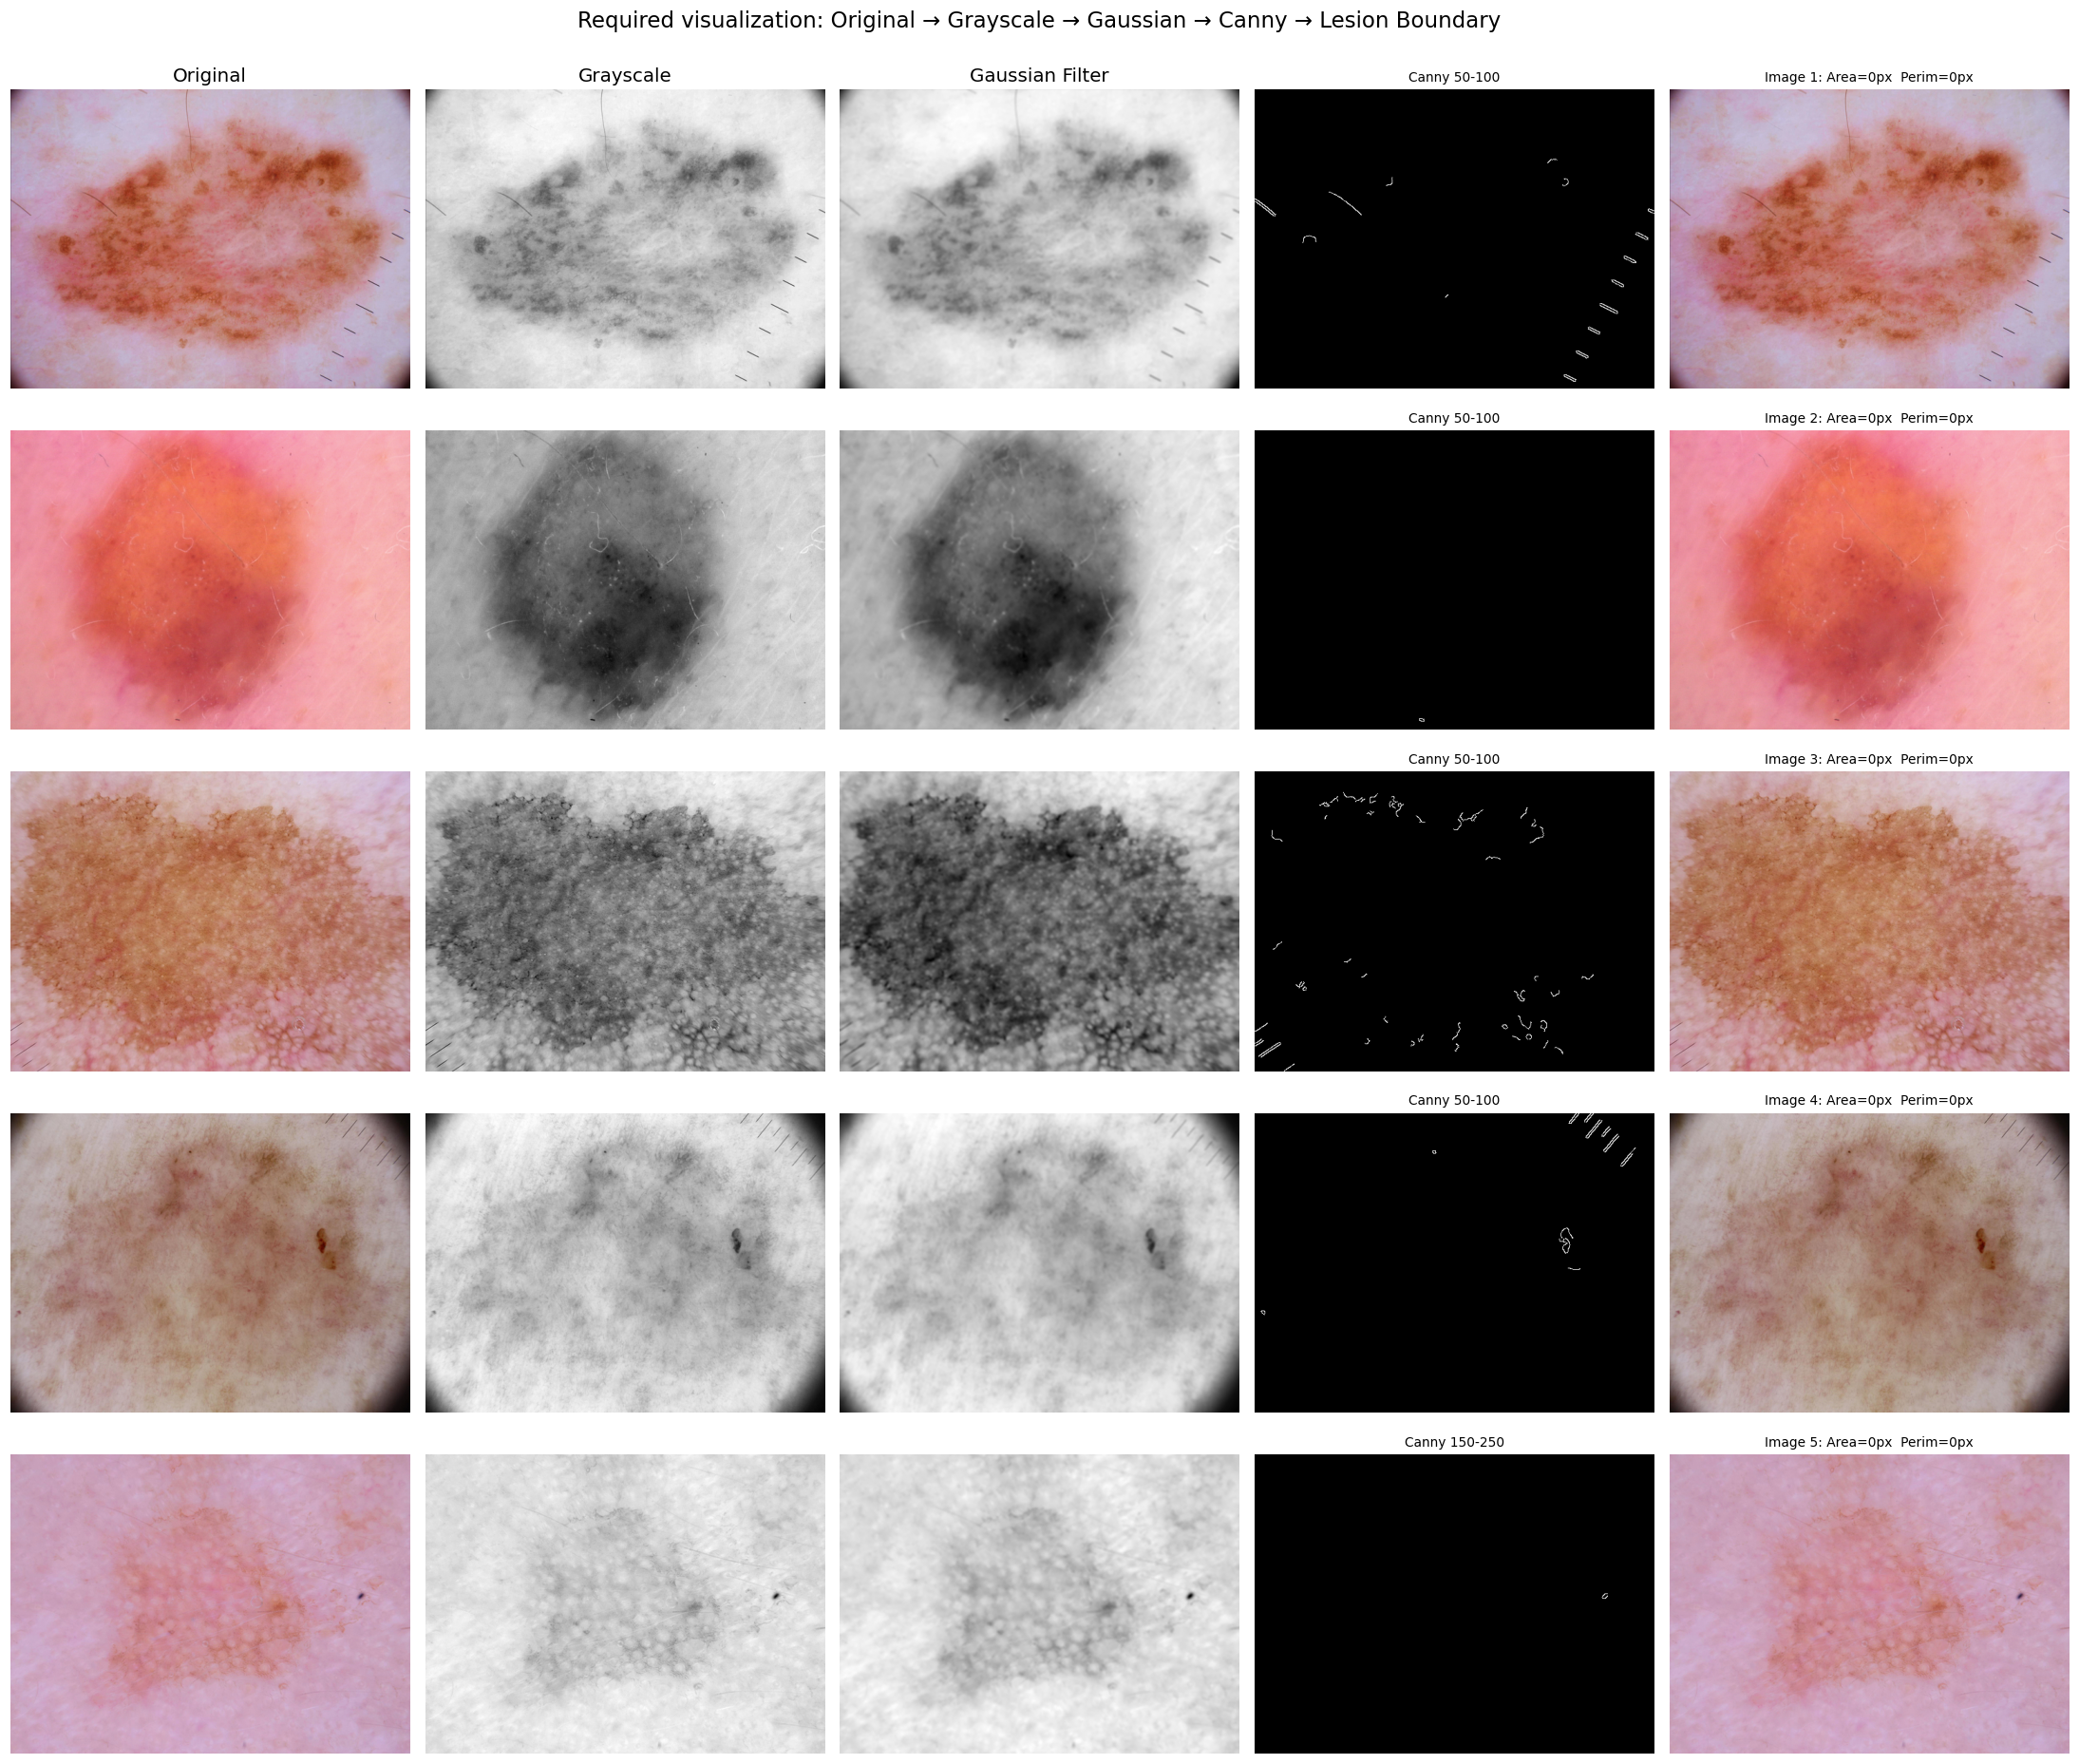

In [8]:
fig, axes = plt.subplots(5, 5, figsize=(20, 17))
titles = ["Original", "Grayscale", "Gaussian Filter", "Canny (best)", "Lesion Boundary"]
summary = []
for i, (im, an) in enumerate(zip(images, analyses)):
    k = an["best"]; r = an["results"][k]
    area, perim = measure(r["contour"], r["mask"])
    panels = [im, an["gray"], an["blur"], r["edges"], overlay(im, r["contour"])]
    for j, p in enumerate(panels):
        ax = axes[i, j]
        ax.imshow(p, cmap=None if j in (0, 4) else "gray")
        ax.axis("off")
        if i == 0: ax.set_title(titles[j], fontsize=13)
    axes[i, 4].set_title(f"{names[i]}: Area={area:,}px  Perim={perim:,.0f}px", fontsize=9)
    axes[i, 3].set_title(f"Canny {k[0]}-{k[1]}", fontsize=9)
    summary.append({"Image": names[i], "Best Filter": "Gaussian (5x5, σ=1.5)",
                    "Edge Method": f"Canny ({k[0]}-{k[1]})",
                    "Area (pixels)": area, "Perimeter (pixels)": round(perim, 1)})
plt.suptitle("Required visualization: Original → Grayscale → Gaussian → Canny → Lesion Boundary",
             fontsize=15, y=1.0)
plt.tight_layout()
os.makedirs("outputs", exist_ok=True)
plt.savefig("outputs/pipeline_results.png", bbox_inches="tight"); plt.show()

In [9]:
results_table = pd.DataFrame(summary)
results_table.to_csv("outputs/results_table.csv", index=False)
display(results_table.style.hide(axis="index").format({"Area (pixels)": "{:,}", "Perimeter (pixels)": "{:,.1f}"}))

Image,Best Filter,Edge Method,Area (pixels),Perimeter (pixels)
Image 1,"Gaussian (5x5, σ=1.5)",Canny (50-100),0,0.0
Image 2,"Gaussian (5x5, σ=1.5)",Canny (50-100),0,0.0
Image 3,"Gaussian (5x5, σ=1.5)",Canny (50-100),0,0.0
Image 4,"Gaussian (5x5, σ=1.5)",Canny (50-100),0,0.0
Image 5,"Gaussian (5x5, σ=1.5)",Canny (150-250),0,0.0


## Final Comparison — 4 filters × 2 edge detectors

Every combination is run on all 5 images (Canny fixed at 100–200, Sobel thresholded with Otsu on the gradient magnitude), then **averaged**:

| Column | Measured by |
|---|---|
| Noise Handling | share of edge pixels lying far (>20 px) from the true border → *lower is better* |
| Edge Quality | edge F1-score vs. reference boundary (5 px tolerance) → *higher is better* |
| Boundary Detection | IoU of the detected lesion region vs. reference → *higher is better* |
| Overall Performance | mean rank of the three metrics |

Labels (Excellent / Good / Fair / Poor) come from the ranking of the 8 methods; the number in brackets is the actual average value.

In [10]:
def sobel_edges(img):
    gx = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)
    mag = np.hypot(gx, gy)
    mag = np.uint8(255 * mag / (mag.max() + 1e-9))
    _, e = cv2.threshold(mag, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return e

FILTERS = {
    "Original": lambda g: g,
    "Average":  lambda g: cv2.blur(g, (5, 5)),
    "Gaussian": lambda g: cv2.GaussianBlur(g, (5, 5), 1.5),
    "Median":   lambda g: cv2.medianBlur(g, 5),
}
EDGES = {"Sobel": sobel_edges, "Canny": lambda g: cv2.Canny(g, 100, 200)}

recs, cache = [], {}
for i, (im, an) in enumerate(zip(images, analyses)):
    gray = an["gray"]
    _, ref_c = reference_mask(gray)
    for fname, f in FILTERS.items():
        fg = f(gray)
        for ename, e_fn in EDGES.items():
            e = e_fn(fg)
            m, c = boundary_from_edges(e)
            met = edge_metrics(e, ref_c, e.shape)
            recs.append(dict(image=names[i], filter=fname, edge=ename, noise=met["noise"],
                             f1=met["f1"], iou=iou(m, an["ref_mask"])))
            cache[(i, fname, ename)] = (e, c)

df = pd.DataFrame(recs)
avg = df.groupby(["filter", "edge"], sort=False)[["noise", "f1", "iou"]].mean()

rk_noise = avg["noise"].rank(method="min", ascending=True)
rk_f1    = avg["f1"].rank(method="min", ascending=False)
rk_iou   = avg["iou"].rank(method="min", ascending=False)
overall  = ((rk_noise + rk_f1 + rk_iou) / 3).rank(method="min")

def lab(rank):
    return ["Excellent", "Good", "Fair", "Poor"][min((int(rank) - 1) // 2, 3)]

final = pd.DataFrame({
    "Method": [f"{f} + {e}" for f, e in avg.index],
    "Noise Handling":     [f"{lab(rk_noise[k])} ({avg.loc[k,'noise']:.2f})" for k in avg.index],
    "Edge Quality":       [f"{lab(rk_f1[k])} ({avg.loc[k,'f1']:.2f})" for k in avg.index],
    "Boundary Detection": [f"{lab(rk_iou[k])} ({avg.loc[k,'iou']:.2f})" for k in avg.index],
    "Overall Performance":[f"{lab(overall[k])} (rank {int(overall[k])})" for k in avg.index],
})
final.to_csv("outputs/final_comparison.csv", index=False)
display(final.style.hide(axis="index"))
best_method = final.loc[overall.values.argmin(), "Method"]
print(f"\n>>> Best overall method on these 5 images: {best_method}")

Method,Noise Handling,Edge Quality,Boundary Detection,Overall Performance
Original + Sobel,Good (0.73),Good (0.15),Good (0.45),Good (rank 4)
Original + Canny,Fair (0.80),Fair (0.04),Fair (0.00),Fair (rank 5)
Average + Sobel,Excellent (0.67),Excellent (0.22),Excellent (0.48),Excellent (rank 1)
Average + Canny,Poor (1.00),Poor (0.00),Fair (0.00),Poor (rank 7)
Gaussian + Sobel,Good (0.68),Good (0.21),Excellent (0.63),Excellent (rank 2)
Gaussian + Canny,Poor (1.00),Poor (0.00),Fair (0.00),Poor (rank 7)
Median + Sobel,Excellent (0.67),Excellent (0.22),Good (0.46),Excellent (rank 2)
Median + Canny,Fair (0.78),Fair (0.01),Fair (0.00),Fair (rank 5)



>>> Best overall method on these 5 images: Average + Sobel


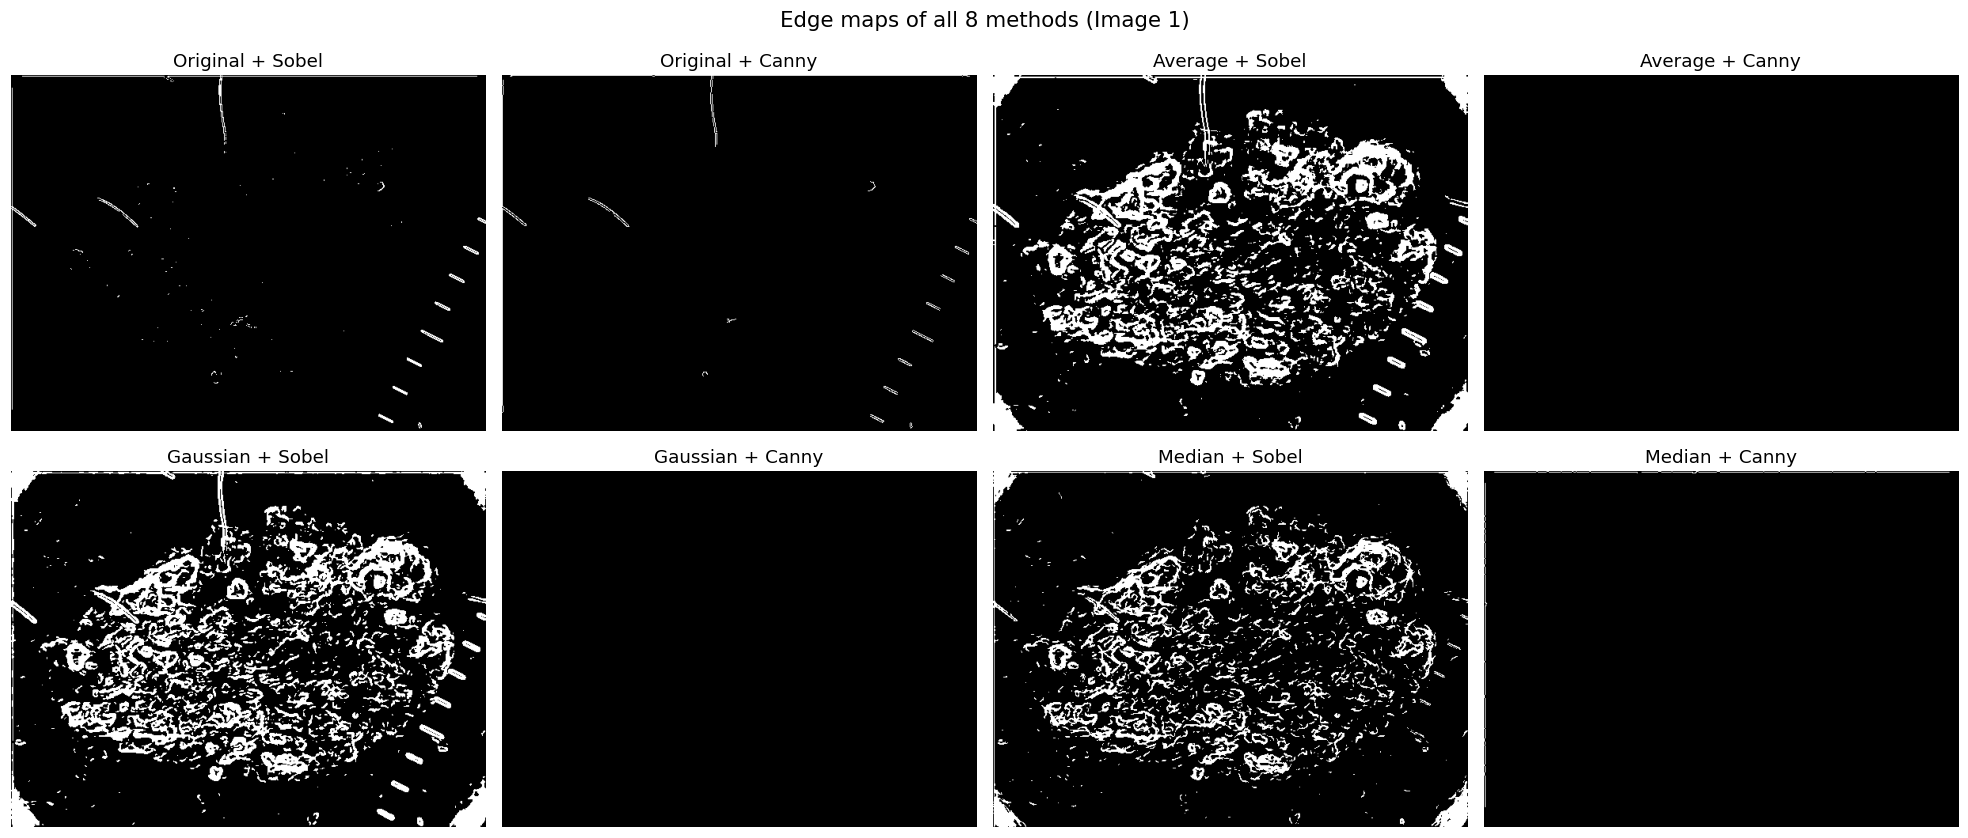

In [11]:
# Visual comparison of all 8 methods on Image 1
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, (fname, ename) in zip(axes.ravel(), [(f, e) for f in FILTERS for e in EDGES]):
    e, c = cache[(0, fname, ename)]
    ax.imshow(e, cmap="gray"); ax.set_title(f"{fname} + {ename}"); ax.axis("off")
plt.suptitle("Edge maps of all 8 methods (Image 1)", fontsize=14)
plt.tight_layout(); plt.savefig("outputs/method_comparison.png", bbox_inches="tight"); plt.show()

## Questions & Answers

In [12]:
best_counts = pd.Series([f"{a['best'][0]}-{a['best'][1]}" for a in analyses]).value_counts()
top_thr = best_counts.index[0]
mean_iou = {f"{k[0]}-{k[1]}": np.mean([a["results"][k]["iou"] for a in analyses]) for k in THRESHOLDS}
mean_den = {f"{k[0]}-{k[1]}": np.mean([a["results"][k]["density"] for a in analyses]) * 100 for k in THRESHOLDS}
mean_noi = {f"{k[0]}-{k[1]}": np.mean([a["results"][k]["noise"] for a in analyses]) for k in THRESHOLDS}
stat = "\n".join(f"  - Canny {t}: edge density {mean_den[t]:.1f}%, noise ratio {mean_noi[t]:.2f}, mean IoU {mean_iou[t]:.2f}"
                  for t in mean_iou)
sel = ", ".join(f"{n}: {a['best'][0]}-{a['best'][1]}" for n, a in zip(names, analyses))

answers = f"""
1. Why is Gaussian filtering applied before Canny detection?
Canny is based on image gradients, and gradients strongly amplify noise (sensor noise, skin texture, small hairs, JPEG artefacts). A Gaussian filter smooths the image so that these small random variations do not create false edges, while the real lesion border (a strong, large-scale intensity change) is preserved. It is also the first step inside the Canny algorithm itself, and unlike an average filter it weights nearby pixels more, so edges are blurred less. Compared with Median it is smoother and gives more continuous edges.

 2. How did the three Canny threshold settings affect the result?
Measured on the 5 images (numbers are computed by the code):
{stat}

In general:

Low thresholds (50–100):** many weak edges are kept → skin texture, hair and shadows appear as extra edges (more noise), and the contour can leak into the surrounding skin.Medium thresholds (100–200):** a good balance – the strong lesion border is kept while most weak texture edges are removed.
High thresholds (150–250):** very clean map, but weak parts of the lesion border (low-contrast regions) disappear, producing gaps, so the boundary can be incomplete or too small.

 3. Which threshold produced the best lesion boundary?
Best threshold per image → {sel}.
The most frequently selected setting was **Canny {top_thr}** (it had the highest overlap with the reference lesion region, IoU, with an acceptable noise level). It gives a continuous boundary around the lesion with few spurious edges, which is exactly what contour detection needs.

 4. Why are edges useful for detecting skin lesions?
A lesion is usually darker/different in colour from the surrounding skin, so its border appears as a strong intensity discontinuity, i.e. an edge. Edge maps reduce the image to the important structure, are fast to compute, need no training data, and the closed edge ring can be converted into a contour from which clinically important features – **area, perimeter, border irregularity** (part of the ABCD rule for melanoma) – can be measured.

 5. What problems did you observe in detecting the lesion boundary?
Hair and dark image corners/vignette** produce strong edges unrelated to the lesion.
Low contrast / blurry borders** (e.g. some nevi and keratoses) give broken edges, so the ring is not closed.
Non-uniform pigment** inside the lesion creates inner edges and sometimes several separate contours.
Specular reflections / skin texture** create small false edges.
 Threshold values that suit one image can fail on another (no single threshold works for all).
 Edge gaps had to be closed with morphological closing, which slightly shifts the border.

 6. How could the method be improved?
 Remove hair first (DullRazor / black-hat filtering + inpainting) and crop the dark vignette.
 Use **adaptive/automatic thresholds** (e.g. median-based or Otsu-based Canny thresholds) for every image.
 Add colour information (use the Lab or the best RGB channel instead of plain grayscale).
 Combine edges with region methods (Otsu, k-means, active contours/GrabCut, watershed) and use convex hull or ellipse fitting to complete broken borders.
 Evaluate against the expert segmentation masks (HAM10000 segmentation dataset) with Dice/IoU, or use a deep model such as U-Net.

display(Markdown(answers))


### 1. Why is Gaussian filtering applied before Canny detection?
Canny is based on image gradients, and gradients strongly amplify noise (sensor noise, skin texture, small hairs, JPEG artefacts). A Gaussian filter smooths the image so that these small random variations do not create false edges, while the real lesion border (a strong, large-scale intensity change) is preserved. It is also the first step inside the Canny algorithm itself, and unlike an average filter it weights nearby pixels more, so edges are blurred less. Compared with Median it is smoother and gives more continuous edges.

### 2. How did the three Canny threshold settings affect the result?
Measured on the 5 images (numbers are computed by the code):
  - Canny 50-100: edge density 0.2%, noise ratio 0.63, mean IoU 0.00
  - Canny 100-200: edge density 0.0%, noise ratio 1.00, mean IoU 0.00
  - Canny 150-250: edge density 0.0%, noise ratio 1.00, mean IoU 0.00

In general:

* **Low thresholds (50–100):** many weak edges are kept → skin texture, hair and shadows appear as extra edges (more noise), and the contour can leak into the surrounding skin.
* **Medium thresholds (100–200):** a good balance – the strong lesion border is kept while most weak texture edges are removed.
* **High thresholds (150–250):** very clean map, but weak parts of the lesion border (low-contrast regions) disappear, producing gaps, so the boundary can be incomplete or too small.

### 3. Which threshold produced the best lesion boundary?
Best threshold per image → Image 1: 50-100, Image 2: 50-100, Image 3: 50-100, Image 4: 50-100, Image 5: 150-250.
The most frequently selected setting was **Canny 50-100** (it had the highest overlap with the reference lesion region, IoU, with an acceptable noise level). It gives a continuous boundary around the lesion with few spurious edges, which is exactly what contour detection needs.

### 4. Why are edges useful for detecting skin lesions?
A lesion is usually darker/different in colour from the surrounding skin, so its border appears as a strong intensity discontinuity, i.e. an edge. Edge maps reduce the image to the important structure, are fast to compute, need no training data, and the closed edge ring can be converted into a contour from which clinically important features – **area, perimeter, border irregularity** (part of the ABCD rule for melanoma) – can be measured.

### 5. What problems did you observe in detecting the lesion boundary?
* **Hair** and **dark image corners/vignette** produce strong edges unrelated to the lesion.
* **Low contrast / blurry borders** (e.g. some nevi and keratoses) give broken edges, so the ring is not closed.
* **Non-uniform pigment** inside the lesion creates inner edges and sometimes several separate contours.
* **Specular reflections / skin texture** create small false edges.
* Threshold values that suit one image can fail on another (no single threshold works for all).
* Edge gaps had to be closed with morphological closing, which slightly shifts the border.

### 6. How could the method be improved?
* Remove hair first (DullRazor / black-hat filtering + inpainting) and crop the dark vignette.
* Use **adaptive/automatic thresholds** (e.g. median-based or Otsu-based Canny thresholds) for every image.
* Add colour information (use the Lab or the best RGB channel instead of plain grayscale).
* Combine edges with region methods (Otsu, k-means, active contours/GrabCut, watershed) and use convex hull or ellipse fitting to complete broken borders.
* Evaluate against the expert segmentation masks (HAM10000 segmentation dataset) with Dice/IoU, or use a deep model such as U-Net.
